# TP 4: Assemble and train the full model

TP1 gave me the data and a bigram that only saw one character. TP2 built one attention head, and TP3 the LayerNorm, the MLP and the residual. Here I assemble them into a small Transformer, train it on Tiny Shakespeare and generate text.

The diagram traces one batch through the model, with the training and generation loops.

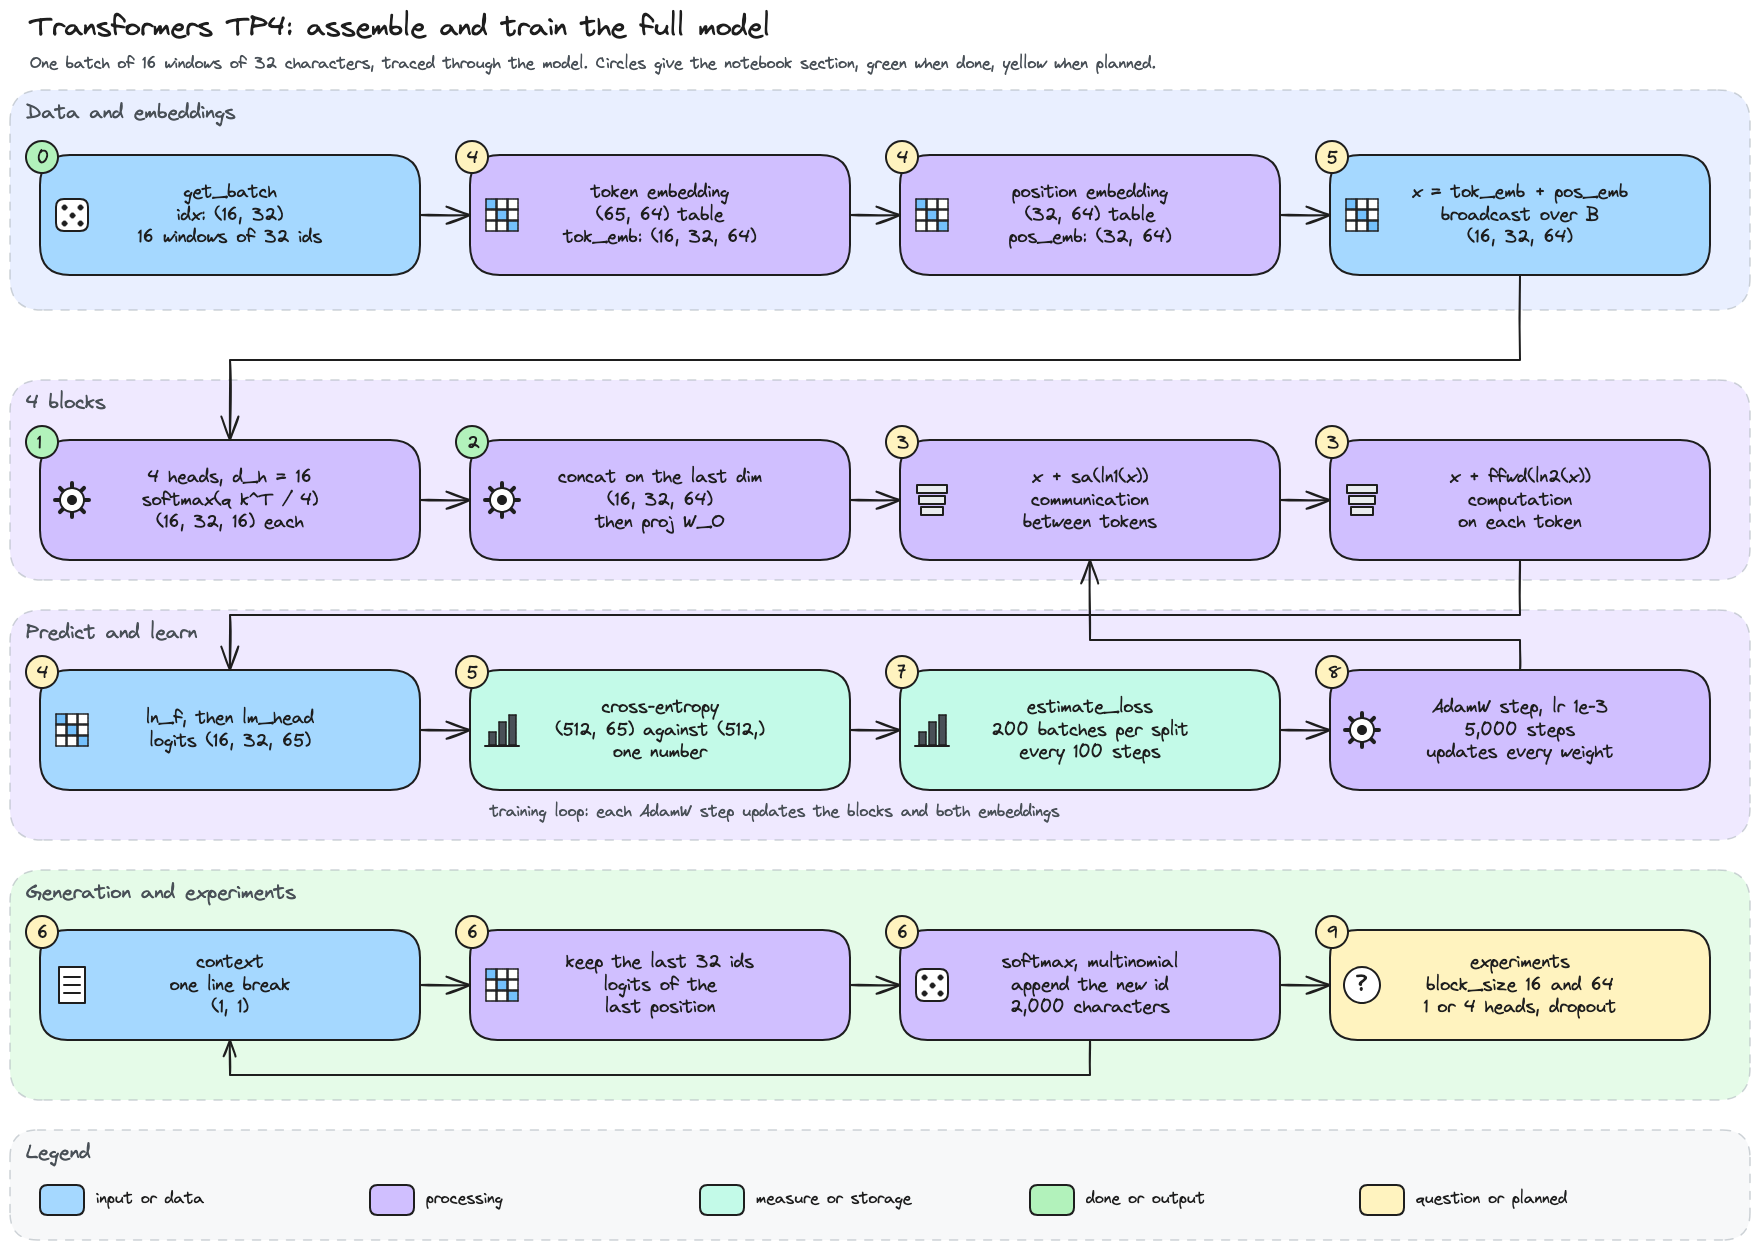

In [1]:
# Workflow diagram: one batch through the full model, with the training and generation loops.
from IPython.display import Image, display

display(Image(filename='diagrams/transformers/tp4_workflow.png', width=900))

## 0. My problem, what I carry over, and the setup

My TP1 bigram stopped at 2.45 nats because each prediction saw a single character. I want a model whose predictions use up to 32 characters, built from the pieces I already checked. The diagram links each lesson of TP1, TP2 and TP3 to what it changes here.

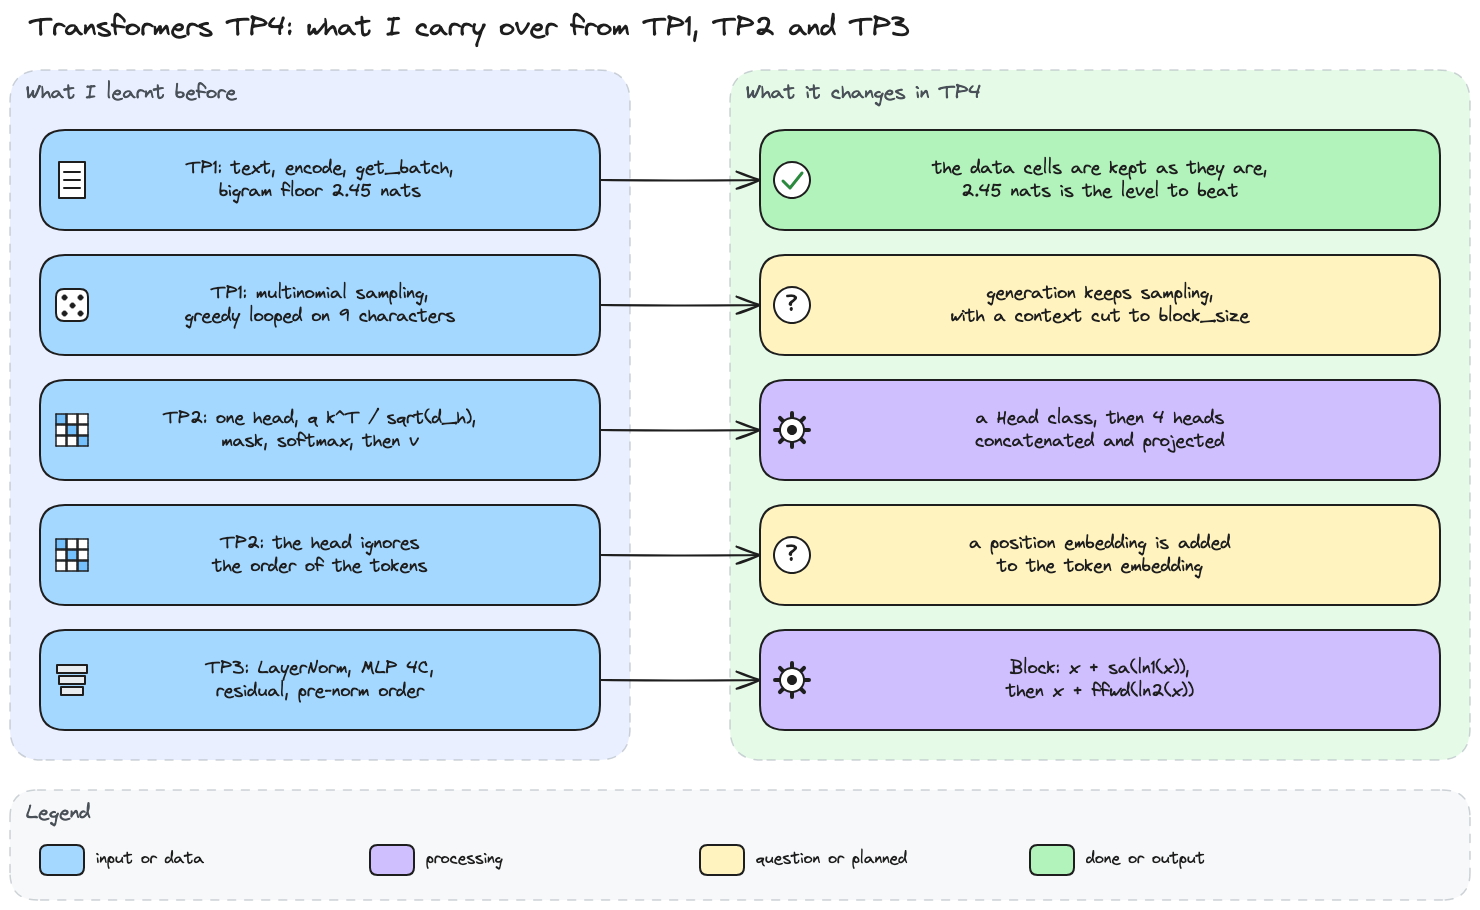

In [2]:
# What I carry over from TP1, TP2 and TP3 (source in diagrams/transformers/).
display(Image(filename='diagrams/transformers/tp4_carry_over.png', width=900))

Before I start, I write down what I expect, so I can check it later.

> *My hypotheses:*
>
> - One head turns (16, 32, 64) into (16, 32, 16), and four heads concatenated give back (16, 32, 64). Sections 1 and 2 check the shapes.
> - Before training, the loss is close to ln(65) = 4.17, since the model favours no character yet. I measure it in section 5.
> - After 5,000 steps, the validation loss falls below the 2.45 nats of my TP1 bigram, because each prediction now sees up to 32 characters.
> - With dropout 0, the train and validation losses stay close, since the model is small next to the 1,003,854 training characters. Sections 8 and 9 follow both curves.
> - The samples gain the layout of the play, with names and line breaks, without correct English.
> - A longer context and more heads lower the validation loss. Section 9 tests block_size 16 and 64, then 1 head against 4.

### My environment

I use the project's `.venv/bin/python` as kernel, with the same dependencies as in the earlier TPs.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
```

I fix seed 42 once here, and the cells that draw weights or batches set their own seed, so every run gives the same numbers.

In [3]:
# Environment: versions, hardware and one seed for random and torch.
import platform
import random
import subprocess
import sys
from importlib.metadata import version

import torch

# Seed fixed once here, and the initial examples set their own seeds too.
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Versions and dependencies
print(f'Python: {platform.python_version()} ({sys.executable})')
for package in ('torch', 'matplotlib', 'ipykernel'):
    print(f'{package}: {version(package)}')

# System and processor
print(f'System: {platform.platform()}, {platform.machine()}')
if sys.platform == 'darwin':
    processor, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processor: {processor}, RAM: {int(ram) / 2**30:g} GiB')

print(f'Seed: {RANDOM_STATE}')

Python: 3.14.7 (/Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python)
torch: 2.14.0
matplotlib: 3.11.1
ipykernel: 7.3.0
System: macOS-26.5-arm64-arm-64bit-Mach-O, arm64
Processor: Apple M3 Max, RAM: 36 GiB
Seed: 42


I keep the constants of the handout, since every class below reads them as globals. The device line picks a CUDA GPU when there is one and the CPU otherwise.

In [4]:
# The constants of the handout, defined before any class that reads them.
batch_size = 16
block_size = 32
max_iters = 5000
eval_interval = 100
learning_rate = 1e-3
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_iters = 200
n_embd = 64
n_head = 4
n_layer = 4
dropout = 0.0

assert n_embd % n_head == 0
print(device)

cpu


The device is `cpu` on my Mac, and the assert passes, so the 64 channels split evenly over the 4 heads. I then bring back my TP1 data cells without changing them.

In [5]:
# The TP1 data cells, kept as they are: download, vocabulary, encode and decode, 90/10 split.
from urllib.request import urlretrieve

url = ("https://raw.githubusercontent.com/karpathy/"
       "char-rnn/master/data/tinyshakespeare/input.txt")
urlretrieve(url, "input.txt")
with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

chars = sorted(list(set(text)))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: ''.join([itos[i] for i in ids])

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

print(f'text: {len(text):,} characters, vocab_size: {vocab_size}')
print(f'train_data: {len(train_data):,} ids, val_data: {len(val_data):,} ids')
print(decode(encode("hii there")))

text: 1,115,394 characters, vocab_size: 65
train_data: 1,003,854 ids, val_data: 111,540 ids
hii there


The text has 1,115,394 characters and 65 distinct ones. The 90/10 split gives 1,003,854 ids for training and 111,540 for validation, the same as in TP1, and `decode(encode(...))` gives `hii there` back.

In [6]:
# Mini-batches as in TP1: random windows of block_size from one split, sent to the device.
def get_batch(split: str) -> tuple[torch.Tensor, torch.Tensor]:
    """B random blocks of one split as inputs x and targets y shifted by one position."""
    source = train_data if split == "train" else val_data
    starts = torch.randint(
        len(source) - block_size, (batch_size,)
    )
    x = torch.stack([
        source[i : i + block_size] for i in starts
    ])
    y = torch.stack([
        source[i + 1 : i + block_size + 1] for i in starts
    ])
    return x.to(device), y.to(device)


torch.manual_seed(1337)
xb, yb = get_batch("train")
print(f'xb {tuple(xb.shape)}, yb {tuple(yb.shape)}, device {xb.device}')
print(f'First window: {decode(xb[0].tolist())!r}')
print(f'Its targets:  {decode(yb[0].tolist())!r}')

xb (16, 32), yb (16, 32), device cpu
First window: "to corrupt a man's wife is\nwhen "
Its targets:  "o corrupt a man's wife is\nwhen s"


A batch now holds 16 windows of 32 ids on the CPU. The first window starts with `to corrupt a man's wife is`, and its targets are the same characters shifted by one, so each of the 32 positions has its own next character to predict. I can now answer the three questions of this setup.

d_h = n_embd / n_head = 64 / 4 = 16
Tokens per batch: 16 x 32 = 512 inputs, and as many targets
Training: 5,000 batches, each with a backward pass
Evaluation: 50 x 2 x 200 = 20,000 batches, forward only
Tokens seen in training: 2,560,000, 2.55 times the train split


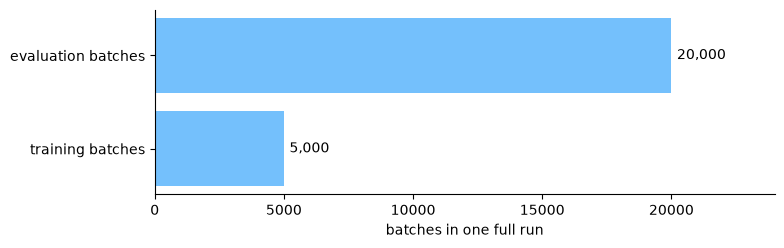

In [7]:
# The questions of the setup: head size, tokens per batch, and the work of a full run.
import matplotlib.pyplot as plt

d_h = n_embd // n_head
tokens_per_batch = batch_size * block_size
evaluations = max_iters // eval_interval  # the loop of section 8 evaluates every eval_interval
eval_batches = evaluations * 2 * eval_iters  # train and val, eval_iters batches each
print(f'd_h = n_embd / n_head = {n_embd} / {n_head} = {d_h}')
print(f'Tokens per batch: {batch_size} x {block_size} = {tokens_per_batch:,} inputs, '
      f'and as many targets')
print(f'Training: {max_iters:,} batches, each with a backward pass')
print(f'Evaluation: {evaluations} x 2 x {eval_iters} = {eval_batches:,} batches, forward only')
print(f'Tokens seen in training: {max_iters * tokens_per_batch:,}, '
      f'{max_iters * tokens_per_batch / len(train_data):.2f} times the train split')

fig, ax = plt.subplots(figsize=(8, 2.4))
work = {'training batches': max_iters, 'evaluation batches': eval_batches}
bars = ax.barh(list(work), list(work.values()), color='#74c0fc')
ax.bar_label(bars, labels=[f'{value:,}' for value in work.values()], padding=4)
ax.set_xlim(0, max(work.values()) * 1.2)
ax.set_xlabel('batches in one full run')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

With 64 channels and 4 heads, each head works on d_h = 16 channels. A batch holds 16 × 32 = 512 input tokens and 512 targets, so one step gives 512 predictions to the loss. The training steps see 2,560,000 tokens, 2.55 times the train split.

A full run trains on 5,000 batches but evaluates on 20,000, four times more, because each of the 50 evaluations averages 200 batches of both splits. The number of evaluations itself is max_iters / eval_interval, so max_iters sets both counts.

> *My conclusion:*
>
> The setup keeps my TP1 data unchanged and runs on the CPU. A full run costs 5,000 training batches and 20,000 evaluation batches, and its training steps see the train split 2.55 times.
>
> My answers to the three questions of the preparation step:
>
> 1. d_h = n_embd / n_head = 64 / 4 = 16.
> 2. A batch holds 16 × 32 = 512 tokens as inputs, and as many targets.
> 3. On the CPU I would first reduce max_iters, since it sets both the 5,000 training batches and the 50 evaluations. Then eval_iters, since evaluation alone takes 20,000 batches.

## 1. Code one head

In TP2 I wrote one head line by line. Here it becomes a class that the next sections can repeat, with its mask stored in the module and a dropout on the weights. I fill the three blanks, then check the shapes and the two choices behind the scale and the mask.

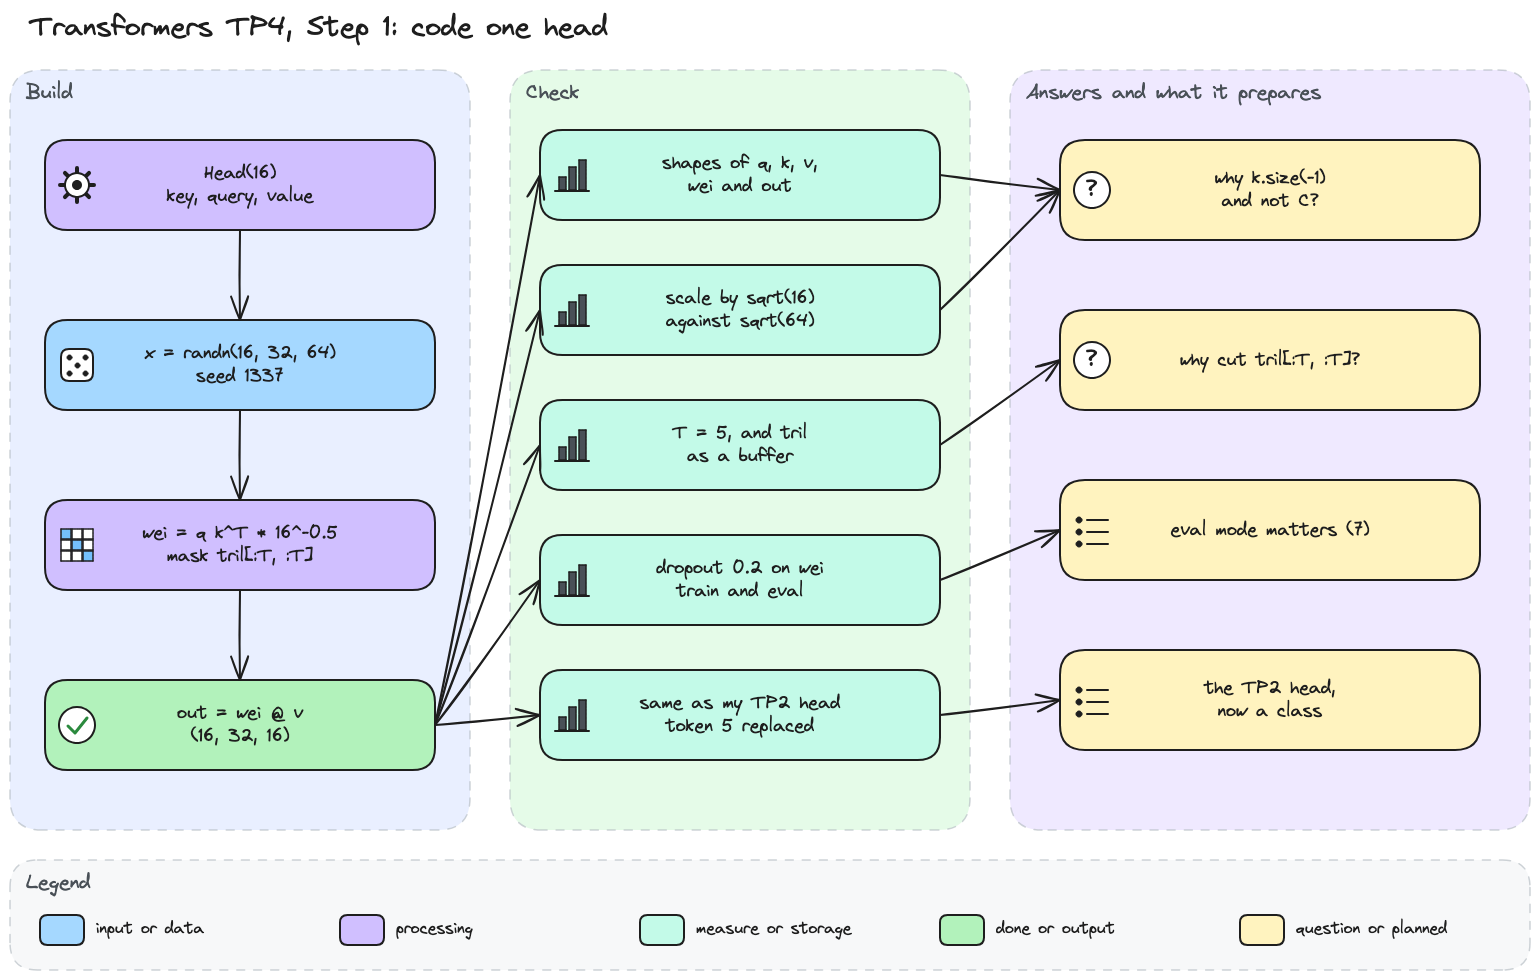

In [8]:
# Step 1 diagram: one head as a class, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp4_step1.png', width=900))

In [9]:
# One attention head as a class: the operations I validated in TP2, with dropout on the weights.
import torch.nn as nn
import torch.nn.functional as F


class Head(nn.Module):
    """One head of causal self-attention, of size head_size."""

    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer(
            'tril', torch.tril(torch.ones(block_size, block_size))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k, q = self.key(x), self.query(x)
        wei = q @ k.transpose(-2, -1) * k.size(-1)**-0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)
        v = self.value(x)
        return wei @ v

I fill the blanks with my lines of TP2. The scale is `k.size(-1)**-0.5`, the mask reads `self.tril[:T, :T]` and the head returns `wei @ v`. I first check the shapes on the input size of the handout.

In [10]:
# Do the shapes match the handout? One head of size 16 on x of shape (16, 32, 64).
torch.manual_seed(1337)
head = Head(16)
x = torch.randn(batch_size, block_size, n_embd)
k, q, v = head.key(x), head.query(x), head.value(x)
wei = q @ k.transpose(-2, -1) * k.size(-1)**-0.5
wei = F.softmax(wei.masked_fill(head.tril == 0, float('-inf')), dim=-1)
out = head(x)
for name, tensor in (('x', x), ('q', q), ('k', k), ('v', v), ('wei', wei), ('out', out)):
    print(f'{name}: {tuple(tensor.shape)}')

x: (16, 32, 64)
q: (16, 32, 16)
k: (16, 32, 16)
v: (16, 32, 16)
wei: (16, 32, 32)
out: (16, 32, 16)


`q`, `k` and `v` have the shape (16, 32, 16), `wei` (16, 32, 32) and `out` (16, 32, 16), as the handout lists. Each of the 32 positions gets one row of 32 weights, and the head returns 16 channels out of the 64 it receives. Four such heads should rebuild 64 channels in section 2.

head of 16, divided by sqrt(k.size(-1) = 16): variance 0.99, last row entropy 2.98
head of 16, divided by sqrt(C = 64): variance 0.25, last row entropy 3.34
head of 64, divided by sqrt(k.size(-1) = 64): variance 1.00, last row entropy 3.03
head of 64, divided by sqrt(C = 64): variance 1.00, last row entropy 3.03
Entropy of a uniform last row over 32 tokens: 3.47


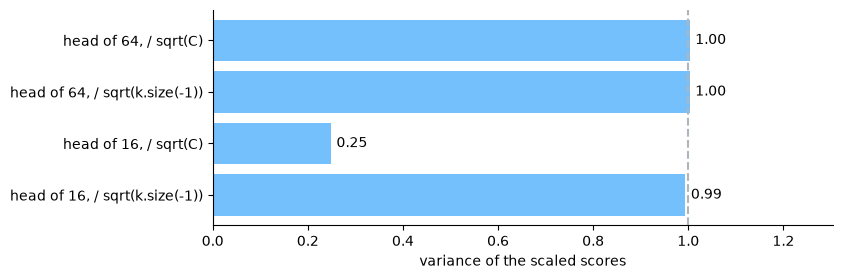

In [11]:
# Why k.size(-1) and not C? Unit-variance q and k, for 4 heads of 16 and for 1 head of 64.
import math

torch.manual_seed(1337)
variances = {}
for head_size in (n_embd // n_head, n_embd):
    q_unit = torch.randn(batch_size, block_size, head_size)
    k_unit = torch.randn(batch_size, block_size, head_size)
    raw = q_unit @ k_unit.transpose(-2, -1)  # each score sums head_size products
    for name, scale in (('k.size(-1)', k_unit.size(-1)), ('C', n_embd)):
        scores = raw * scale**-0.5
        last = F.softmax(scores.masked_fill(head.tril == 0, float('-inf')), dim=-1)[:, -1]
        entropy = -(last * torch.log(last.clamp_min(1e-12))).sum(dim=-1).mean()
        variances[f'head of {head_size}, / sqrt({name})'] = scores.var().item()
        print(f'head of {head_size}, divided by sqrt({name} = {scale}): '
              f'variance {scores.var():.2f}, last row entropy {entropy:.2f}')
print(f'Entropy of a uniform last row over {block_size} tokens: {math.log(block_size):.2f}')

fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(list(variances), list(variances.values()), color='#74c0fc')
ax.bar_label(bars, labels=[f'{value:.2f}' for value in variances.values()], padding=4)
ax.axvline(1, linestyle='--', color='#adb5bd')
ax.set_xlim(0, max(variances.values()) * 1.3)
ax.set_xlabel('variance of the scaled scores')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Each score sums k.size(-1) products, so its variance follows the head size and not C. For a head of 16, dividing by √16 gives a variance of 0.99, while dividing by √C = √64 gives 0.25. The rows then get flatter, with an entropy of 3.34 against 2.98, close to the 3.47 of a uniform row.

For a single head of 64, both choices give 1.00, since k.size(-1) = C there. So k.size(-1) keeps the scores at variance 1 whatever the number of heads, which matters for my test of 1 head against 4 in section 9.

In [12]:
# Why cut tril[:T, :T]? A context of 5 tokens, with the cut and with the full 32 x 32 mask.
short = x[:, :5]
print(f'Head on a context of 5 tokens: {tuple(head(short).shape)}')
scores = head.query(short) @ head.key(short).transpose(-2, -1)
try:
    scores.masked_fill(head.tril == 0, float('-inf'))
except RuntimeError as error:
    print(f'With the full mask: {error}')

print(f'Parameters: {sum(p.numel() for p in head.parameters()):,}, buffers: '
      f'{[(name, tuple(b.shape)) for name, b in head.named_buffers()]}')
print(f'tril in the state_dict: {"tril" in head.state_dict()}, '
      f'tril learned: {head.tril.requires_grad}')

Head on a context of 5 tokens: (16, 5, 16)
With the full mask: The size of tensor a (32) must match the size of tensor b (5) at non-singleton dimension 2
Parameters: 3,072, buffers: [('tril', (32, 32))]
tril in the state_dict: True, tril learned: False


On a context of 5 tokens the head returns (16, 5, 16), because the mask is cut to 5 × 5. The full 32 × 32 mask fails against 5 × 5 scores, with a size mismatch at dimension 2. Generation starts from a single character and grows up to block_size, so the head must work for every T up to 32.

The mask is a buffer, outside the 3,072 learned parameters. It is saved in the state_dict and never learned.

train mode: row sums from 0.000 to 1.250, visible weights set to 0: 19.67%
eval mode: row sums from 1.000 to 1.000, visible weights set to 0: 0.00%
TP4 value dropout = 0.0: weights unchanged in train mode True


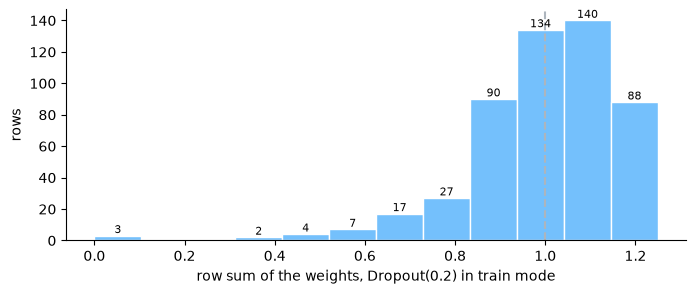

In [13]:
# What would dropout do to the weights? A copy of the head with Dropout(0.2), train then eval.
import copy

noisy = copy.deepcopy(head)
noisy.dropout = nn.Dropout(0.2)
k_noisy = noisy.key(x)
scores = noisy.query(x) @ k_noisy.transpose(-2, -1) * k_noisy.size(-1)**-0.5
clean = F.softmax(scores.masked_fill(noisy.tril == 0, float('-inf')), dim=-1).detach()
visible = noisy.tril.bool().expand_as(clean)  # the weights on past and current tokens
row_sums = {}
for mode in ('train', 'eval'):
    noisy.train(mode == 'train')
    dropped = noisy.dropout(clean)
    row_sums[mode] = dropped.sum(dim=-1).flatten()
    print(f'{mode} mode: row sums from {row_sums[mode].min():.3f} to {row_sums[mode].max():.3f}, '
          f'visible weights set to 0: {100 * (dropped[visible] == 0).float().mean():.2f}%')
print(f'TP4 value dropout = {dropout}: weights unchanged in train mode '
      f'{torch.equal(head.dropout(clean), clean)}')

fig, ax = plt.subplots(figsize=(8, 3))
counts, _, bars = ax.hist(row_sums['train'], bins=12, color='#74c0fc', edgecolor='white')
ax.bar_label(bars, labels=[int(c) if c else '' for c in counts], fontsize=8)
ax.axvline(1, linestyle='--', color='#adb5bd')
ax.set_xlabel('row sum of the weights, Dropout(0.2) in train mode')
ax.set_ylabel('rows')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

With Dropout(0.2) in train mode, 19.67% of the visible weights become 0 and the others are multiplied by 1/0.8 = 1.25. Row sums then spread from 0.000 to 1.250, so a row no longer averages the values, and the row of the first token can lose its only weight. In eval mode every row sums to 1.000 again.

With the TP4 value of 0.0 the weights stay unchanged. Eval mode will matter in section 7 as soon as I raise dropout in section 9.

In [14]:
# Is this my TP2 head? The TP2 lines with the same layers, then token 5 replaced.
tril = torch.tril(torch.ones(block_size, block_size))
wei_tp2 = q @ k.transpose(-2, -1) * k.size(-1)**-0.5  # TP2 section 5, line by line
wei_tp2 = wei_tp2.masked_fill(tril == 0, float('-inf'))
wei_tp2 = F.softmax(wei_tp2, dim=-1)
print(f'Class against the TP2 lines: allclose {torch.allclose(head(x), wei_tp2 @ v)}')

changed = x.clone()
changed[0, 5] = torch.randn(n_embd)
moves = (head(changed) - head(x))[0].abs().max(dim=-1).values.detach()
print(f'Token 5 replaced, largest change of rows 0 to 7: '
      f'{[round(m, 2) for m in moves[:8].tolist()]}')
print(f'Rows 0 to 4 unchanged: {torch.equal(head(changed)[0, :5], head(x)[0, :5])}')

Class against the TP2 lines: allclose True
Token 5 replaced, largest change of rows 0 to 7: [0.0, 0.0, 0.0, 0.0, 0.0, 0.26, 0.14, 0.12]
Rows 0 to 4 unchanged: True


The class gives the same output as my TP2 lines with the same layers, with allclose True. Replacing token 5 changes rows 5, 6 and 7 by 0.26, 0.14 and 0.12 and leaves rows 0 to 4 unchanged, so the mask still keeps the future out. My TP2 head is now a module I can repeat.

> *My conclusion:*
>
> My `Head` class computes the masked and scaled attention of TP2, stores its mask as a 32 × 32 buffer and applies dropout to the weights. On (16, 32, 64) it returns (16, 32, 16) through weights of (16, 32, 32), so the first half of my first hypothesis holds. Section 2 checks the second half, four heads back to 64 channels.
>
> My answers to the two questions of this step:
>
> 1. The scale uses k.size(-1) because each score sums that many products. For a head of 16 it keeps the variance at 0.99, while C = 64 would shrink it to 0.25 and flatten the rows.
> 2. The mask is cut to tril[:T, :T] because T can be shorter than block_size, as in generation. A context of 5 tokens works with the cut and fails with the full 32 × 32 mask.

## 2. Combine several heads

One head gives one way of weighting the past, with 16 channels. I run four heads side by side, concatenate their outputs back to 64 channels and mix them with a projection. I fill the blank, check the shapes, then test the two choices behind the concatenation.

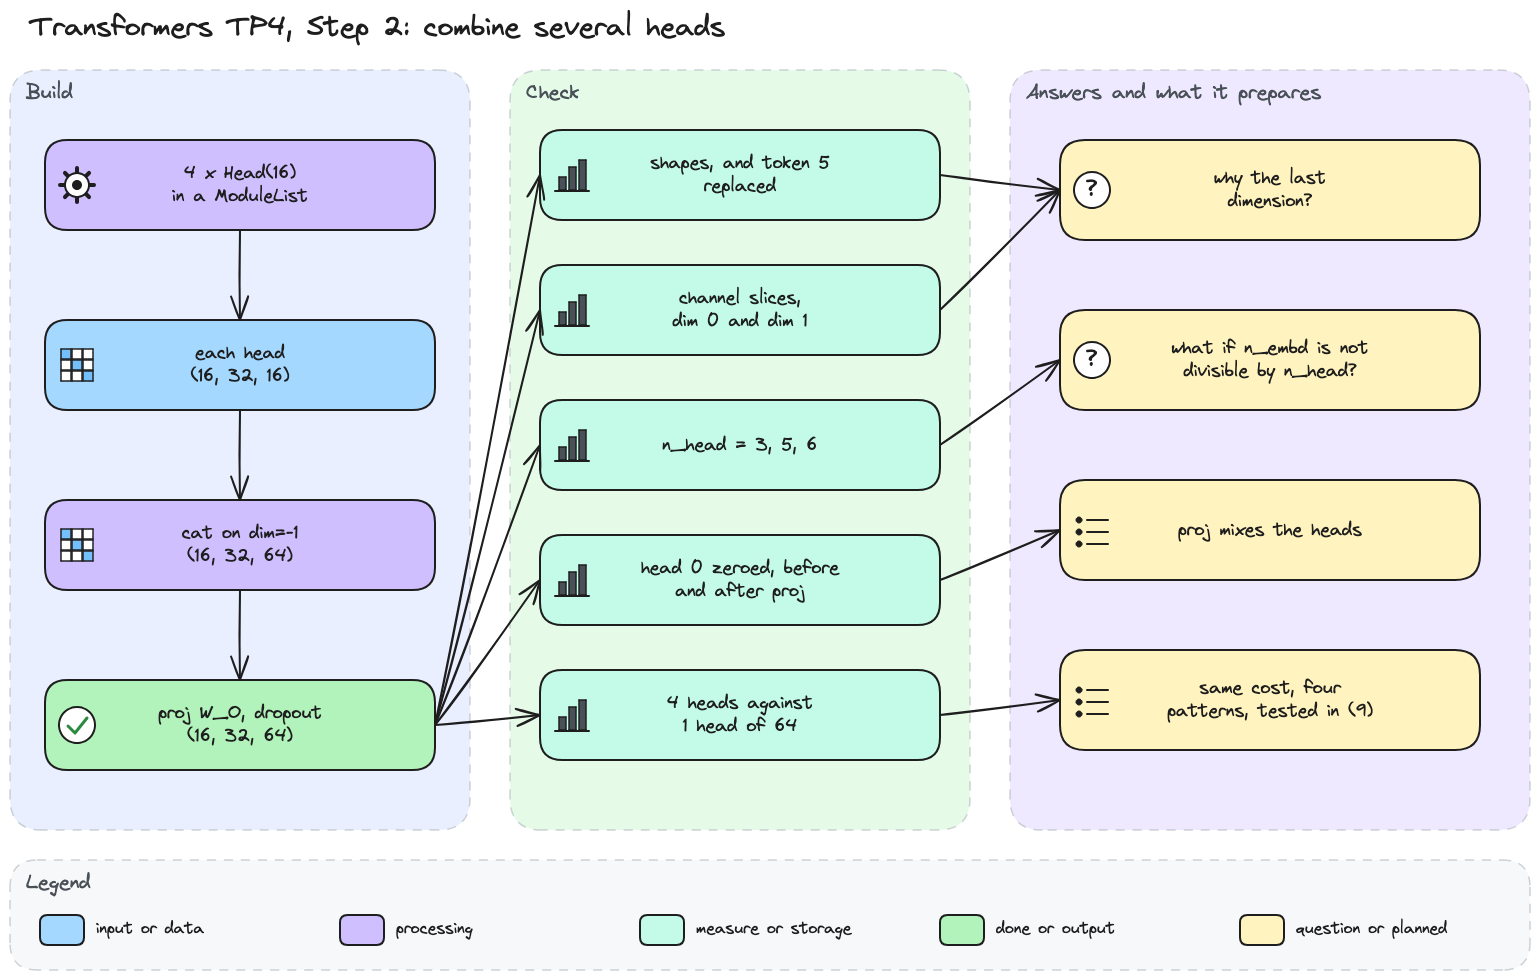

In [15]:
# Step 2 diagram: four heads concatenated then projected, and the checks behind my answers.
display(Image(filename='diagrams/transformers/tp4_step2.png', width=900))

In [16]:
# Several heads in parallel: concatenate their outputs, then mix them with a projection.
class MultiHeadAttention(nn.Module):
    """num_heads heads of size head_size, concatenated and projected back to n_embd."""

    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([
            Head(head_size) for _ in range(num_heads)
        ])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat(
            [h(x) for h in self.heads], dim=-1
        )
        return self.dropout(self.proj(out))

The blank is `dim=-1`, the channels of each head. Each head gets head_size = n_embd // n_head, so four heads should give back the 64 channels that `proj` expects.

In [17]:
# Do four heads give back 64 channels? Shapes of each head, the concatenation and the output.
torch.manual_seed(1337)
head_size = n_embd // n_head
sa = MultiHeadAttention(n_head, head_size)
x = torch.randn(batch_size, block_size, n_embd)
head_outs = [h(x) for h in sa.heads]
concat = torch.cat(head_outs, dim=-1)
out = sa(x)
print(f'Each head: {[tuple(o.shape) for o in head_outs]}')
print(f'Concatenation: {tuple(concat.shape)}, after proj: {tuple(out.shape)}')
print(f'Parameters: heads {sum(p.numel() for p in sa.heads.parameters()):,}, '
      f'proj {sum(p.numel() for p in sa.proj.parameters()):,}, '
      f'total {sum(p.numel() for p in sa.parameters()):,}')

changed = x.clone()
changed[0, 5] = torch.randn(n_embd)
print(f'Token 5 replaced, rows 0 to 4 unchanged: {torch.equal(sa(changed)[0, :5], out[0, :5])}')

Each head: [(16, 32, 16), (16, 32, 16), (16, 32, 16), (16, 32, 16)]
Concatenation: (16, 32, 64), after proj: (16, 32, 64)
Parameters: heads 12,288, proj 4,160, total 16,448
Token 5 replaced, rows 0 to 4 unchanged: True


Each head returns (16, 32, 16), and the four of them concatenated give (16, 32, 64), the size of `x`. The projection keeps (16, 32, 64), so the second half of my first hypothesis holds. The module has 16,448 parameters, 12,288 in the heads and 4,160 in `proj`.

Replacing token 5 still leaves rows 0 to 4 unchanged, so putting causal heads together keeps the future out.

In [18]:
# Why the last dimension? Each slice of 16 channels, then the concatenation on dim 0 and dim 1.
for h, head_out in enumerate(head_outs):
    piece = concat[..., head_size * h:head_size * (h + 1)]
    print(f'channels {head_size * h} to {head_size * (h + 1) - 1} are head {h}: '
          f'{torch.equal(piece, head_out)}')
for dim in (0, 1):
    wrong = torch.cat(head_outs, dim=dim)
    try:
        sa.proj(wrong)
    except RuntimeError as error:
        print(f'cat on dim={dim}: {tuple(wrong.shape)}, proj fails: {error}')

channels 0 to 15 are head 0: True
channels 16 to 31 are head 1: True
channels 32 to 47 are head 2: True
channels 48 to 63 are head 3: True
cat on dim=0: (64, 32, 16), proj fails: mat1 and mat2 shapes cannot be multiplied (2048x16 and 64x64)
cat on dim=1: (16, 128, 16), proj fails: mat1 and mat2 shapes cannot be multiplied (2048x16 and 64x64)


Each block of 16 channels of the concatenation is exactly one head, from channels 0 to 15 for head 0 up to 48 to 63 for head 3. Concatenating on dim 0 gives (64, 32, 16), as if there were 64 sequences, and on dim 1 gives (16, 128, 16), as if each sequence had 128 positions. In both cases `proj` fails, since it expects 64 channels per token.

The last dimension is the only one where the four heads describe the same token side by side.

In [19]:
# What if n_embd is not divisible by n_head? Three head counts that do not divide 64.
for count in (3, 5, 6):
    size = n_embd // count
    trial = MultiHeadAttention(count, size)
    try:
        trial(x)
    except RuntimeError as error:
        print(f'n_head = {count}: head_size {size}, {count * size} channels after cat, '
              f'{n_embd} % {count} = {n_embd % count}, proj fails: {error}')

n_head = 3: head_size 21, 63 channels after cat, 64 % 3 = 1, proj fails: mat1 and mat2 shapes cannot be multiplied (512x63 and 64x64)
n_head = 5: head_size 12, 60 channels after cat, 64 % 5 = 4, proj fails: mat1 and mat2 shapes cannot be multiplied (512x60 and 64x64)
n_head = 6: head_size 10, 60 channels after cat, 64 % 6 = 4, proj fails: mat1 and mat2 shapes cannot be multiplied (512x60 and 64x64)


With 3, 5 or 6 heads, the integer division gives heads of 21, 12 or 10 channels, and the concatenation has 63, 60 or 60 channels instead of 64. The remainder 64 % n_head is lost, and `proj`, built for 64 inputs, fails. The assert of section 0 stops this case before any class runs.

Channels changed in the concatenation: 16 of 64
Channels changed after proj: 64 of 64


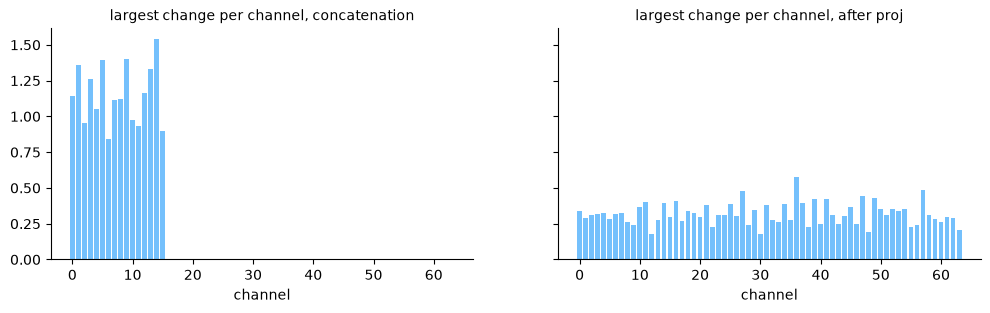

In [20]:
# Where do the heads meet? Head 0 set to zero, before and after the projection.
muted = concat.clone()
muted[..., :head_size] = 0
before = (muted - concat).abs().amax(dim=(0, 1)).detach()
after = (sa.proj(muted) - sa.proj(concat)).abs().amax(dim=(0, 1)).detach()
print(f'Channels changed in the concatenation: {(before > 0).sum().item()} of {n_embd}')
print(f'Channels changed after proj: {(after > 0).sum().item()} of {n_embd}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
for ax, change, title in ((axes[0], before, 'concatenation'), (axes[1], after, 'after proj')):
    ax.bar(range(n_embd), change, color='#74c0fc')
    ax.set_xlabel('channel')
    ax.set_title(f'largest change per channel, {title}', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

Setting head 0 to zero changes only its 16 channels in the concatenation, and the 48 others keep their values. After `proj`, all 64 channels change, by smaller amounts spread over every channel. The concatenation only puts the heads side by side, and `proj` is where each output channel mixes all of them.

Attention parameters: 4 heads of 16 12,288, 1 head of 64 12,288
Largest gap between the weights of two heads: 0.42
Last row entropy per head: [3.41, 3.43, 3.42, 3.41], uniform 3.47
Cosine between the outputs of two heads: from 0.010 to 0.085


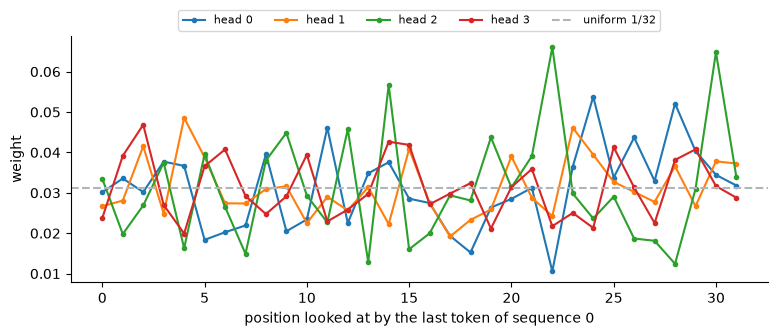

In [21]:
# Four heads of 16 or one head of 64? Same attention parameters, but how many patterns?
one = MultiHeadAttention(1, n_embd)
print(f'Attention parameters: 4 heads of 16 {sum(p.numel() for p in sa.heads.parameters()):,}, '
      f'1 head of 64 {sum(p.numel() for p in one.heads.parameters()):,}')

patterns = []
for h in sa.heads:
    k_h = h.key(x)
    scores = h.query(x) @ k_h.transpose(-2, -1) * k_h.size(-1)**-0.5
    patterns.append(F.softmax(scores.masked_fill(h.tril == 0, float('-inf')), dim=-1).detach())
gaps = [(a - b).abs().max().item() for i, a in enumerate(patterns) for b in patterns[i + 1:]]
entropies = [-(w[:, -1] * torch.log(w[:, -1])).sum(dim=-1).mean().item() for w in patterns]
cosines = [F.cosine_similarity(a.flatten(), b.flatten(), dim=0).item()
           for i, a in enumerate(head_outs) for b in head_outs[i + 1:]]
print(f'Largest gap between the weights of two heads: {max(gaps):.2f}')
print(f'Last row entropy per head: {[round(e, 2) for e in entropies]}, '
      f'uniform {math.log(block_size):.2f}')
print(f'Cosine between the outputs of two heads: from {min(cosines):.3f} to {max(cosines):.3f}')

fig, ax = plt.subplots(figsize=(9, 3.2))
for h, pattern in enumerate(patterns):
    ax.plot(range(block_size), pattern[0, -1], marker='o', markersize=3, label=f'head {h}')
ax.axhline(1 / block_size, linestyle='--', color='#adb5bd', label='uniform 1/32')
ax.set_xlabel('position looked at by the last token of sequence 0')
ax.set_ylabel('weight')
ax.legend(fontsize=8, ncols=5, loc='lower center', bbox_to_anchor=(0.5, 1.0))
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Four heads of 16 and one head of 64 both use 12,288 attention parameters, so splitting costs nothing. The four heads already weight the past differently, with weights up to 0.42 apart and almost unrelated outputs, with cosines from 0.010 to 0.085. Their last rows stay close to uniform before training, with entropies from 3.41 to 3.43 against 3.47.

One head of 64 would give a single pattern for the same price, which I compare after training in section 9.

> *My conclusion:*
>
> `MultiHeadAttention` runs four heads of 16 channels, puts their outputs side by side on the last dimension and mixes them with `proj`. The output keeps the shape (16, 32, 64) of `x` and still ignores the future, so my first hypothesis holds in full. Four heads cost the same 12,288 attention parameters as one head of 64, and section 3 puts this module inside a block.
>
> My answers to the two questions of this step:
>
> 1. I concatenate on the last dimension because it holds the channels of each token. Each block of 16 channels is one head, while dim 0 or dim 1 would create fake sequences or positions, and `proj` fails on both.
> 2. If n_embd is not divisible by n_head, the heads lose the remainder, for example 60 channels for 5 heads, and `proj(64, 64)` fails. The assert of section 0 catches it first.

## 3. Assemble a block

I will reuse my MLP of TP3 and alternate attention and feed-forward, each with its LayerNorm and its residual addition. The order of these operations, and which one is communication or computation, are what I want to settle.

## 4. Define the layers of the model

I will add a token embedding, a position embedding and a final layer that maps back to the 65 characters. I want the shape of each matrix, and the reason why lm_head is now separate from the embedding.

## 5. Write the forward pass and the loss

I will add the two embeddings, run the blocks and compute the cross-entropy only when targets are given. The broadcast of the position embedding and the loss before training are what I check first.

## 6. Generate with a limited context

I will generate one character at a time and keep only the last block_size characters as context. I want to see why no gradient is needed here, and why I sample instead of taking the argmax.

## 7. Evaluate

I will use the provided `estimate_loss`, which averages the loss over many batches of each split. I want to understand why it switches the model to eval mode and back to train mode.

## 8. Train

I will complete the AdamW loop and follow the train and validation losses every 100 steps. A validation loss that rises while the train loss falls would be my sign of overfitting.

## 9. Train, generate and experiment

I will compare the text before and after training and plot both losses. Then I test block_size 16 and 64, one head against four at the same n_embd, and more dropout if overfitting appears.

## Summary of the four TPs

I will link each class to the idea it implements across the four TPs. I want to say which brick creates the context, which transforms a token, which produces the logits, and where the loss acts on the whole model.